In [20]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import sys
from scipy.fft import fft2

# Append the parent directory to find your dataset script
sys.path.append('..')
from datasets.super_res_dataset_fourier import SuperResDataset

In [21]:
hr_files = ['../data/100/window_2003.npy']
sigma = 5

# Initialize the dataset using the frequency downsampling pipeline
dataset = SuperResDataset(hr_files=hr_files, downsample_factor=1, freq_threshold=sigma)

# Pull the first sample (returns [C, H, W] tensors)
lr_tensor, hr_tensor = dataset[0]

# Convert tensors to numpy arrays for plotting and spectrum calculation
lr_np = lr_tensor.numpy()
hr_np = hr_tensor.numpy()

(1000, 128, 128, 6)


In [22]:
def compute_energy_spectrum(velocity_field: np.ndarray):
    u = velocity_field[0]
    v = velocity_field[1]
    
    # Remove the mean (background flow)
    u_prime = u - np.mean(u)
    v_prime = v - np.mean(v)
    nx, ny = u.shape
    
    # Frequency grids
    kx = np.fft.fftfreq(nx) * nx
    ky = np.fft.fftfreq(ny) * ny
    kx_grid, ky_grid = np.meshgrid(kx, ky, indexing="ij")
    k = np.sqrt(kx_grid**2 + ky_grid**2)
    
    # 2D Fourier transforms of the velocity components
    e_u = np.abs(fft2(u_prime)) ** 2
    e_v = np.abs(fft2(v_prime)) ** 2
    e_k = 0.5 * (e_u + e_v)
    
    # Radially bin the energies into 1D spectrum
    k_bins = np.arange(0.1, np.max(k) / 2 + 1, 1)
    valid_bins = []
    valid_energy = []
    
    for i, k_min in enumerate(k_bins[:-1]):
        k_max = k_bins[i + 1]
        mask = (k >= k_min) & (k < k_max)
        if np.count_nonzero(mask) >= 5:
            valid_bins.append(k_min)
            valid_energy.append(np.mean(e_k[mask]))
            
    return np.array(valid_bins), np.array(valid_energy)

# Compute spectra for both LR and HR fields
k_lr, e_lr = compute_energy_spectrum(lr_np)
k_hr, e_hr = compute_energy_spectrum(hr_np)

C:\Users\vinic\AppData\Local\Temp\ipykernel_21596\1401202165.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(h_pad=2.0)


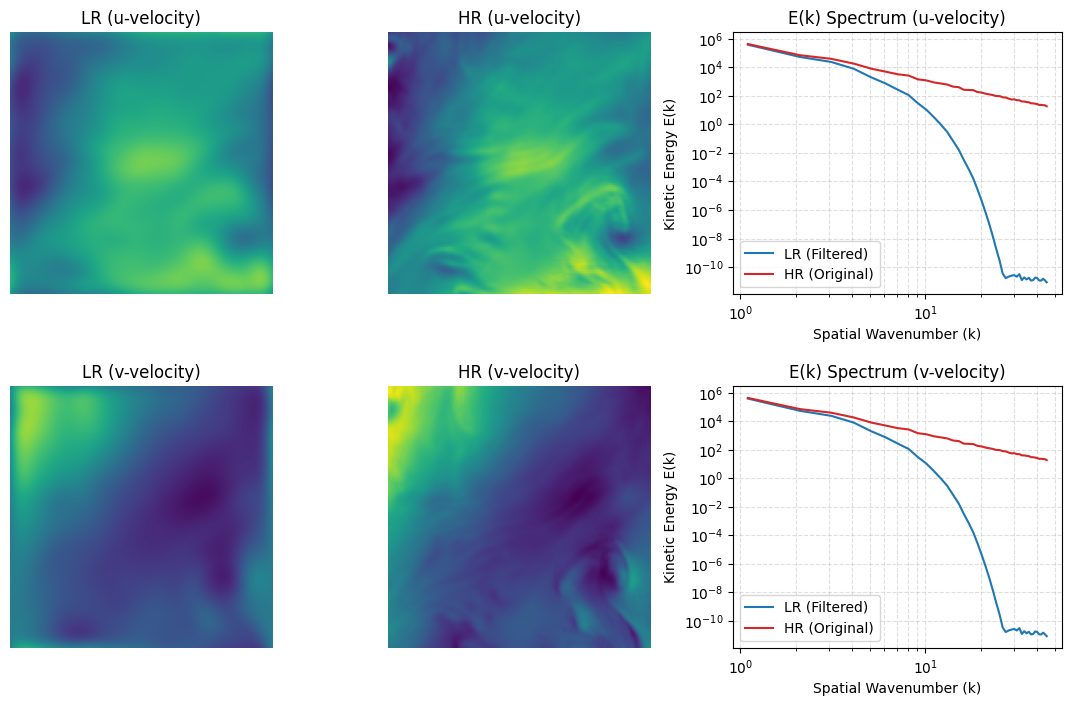

In [23]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 8),
    gridspec_kw={"width_ratios": [1, 1, 1], "wspace": 0.15, "hspace": 0.35}
)

variables = ["u-velocity", "v-velocity"]

for row, comp_name in enumerate(variables):
    # Determine color limits based on both fields so they share the exact same scale
    vmin = min(lr_np[row].min(), hr_np[row].min())
    vmax = max(lr_np[row].max(), hr_np[row].max())
    
    # Column 1: Low Resolution Input
    axes[row, 0].imshow(lr_np[row], vmin=vmin, vmax=vmax, cmap="viridis")
    axes[row, 0].set_title(f"LR ({comp_name})")
    axes[row, 0].axis("off")
    
    # Column 2: High Resolution Ground Truth
    axes[row, 1].imshow(hr_np[row], vmin=vmin, vmax=vmax, cmap="viridis")
    axes[row, 1].set_title(f"HR ({comp_name})")
    axes[row, 1].axis("off")
    
    # Column 3: Kinetic Energy Spectrum (Log-Log)
    axes[row, 2].loglog(k_lr, e_lr, label="LR (Filtered)", color="tab:blue")
    axes[row, 2].loglog(k_hr, e_hr, label="HR (Original)", color="tab:red")
    axes[row, 2].set_xlabel("Spatial Wavenumber (k)")
    axes[row, 2].set_ylabel("Kinetic Energy E(k)")
    axes[row, 2].set_title(f"E(k) Spectrum ({comp_name})")
    axes[row, 2].grid(True, which="both", linestyle="--", alpha=0.4)
    axes[row, 2].legend()

# Added h_pad to ensure the tight_layout algorithm respects vertical text boundaries
plt.tight_layout(h_pad=2.0)
plt.savefig('ke_spectrum_comparison.png', bbox_inches='tight', dpi=300)
plt.show()